<a href="https://colab.research.google.com/github/kamalika1191-cloud/bias-audit-mlops/blob/main/notebooks/02_baseline_and_bias_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 · Baseline model and first bias audit
**Goal:** train a simple screening model (TF-IDF + logistic regression) that reads a biography and predicts the occupation, then measure its gender bias with the **TPR gap**.

**TPR gap, in plain words:** for each job, the share of real women the model recognises as that job, minus the share of real men. 0 = equal treatment. Negative = women are recognised less often.

Run each cell from top to bottom with **Shift + Enter**. Training takes a few minutes.

## 1. Load the data

In [1]:
!pip install -q datasets mlflow

from datasets import load_dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROFESSIONS = ["accountant", "architect", "attorney", "chiropractor", "comedian", "composer",
               "dentist", "dietitian", "dj", "filmmaker", "interior_designer", "journalist",
               "model", "nurse", "painter", "paralegal", "pastor", "personal_trainer",
               "photographer", "physician", "poet", "professor", "psychologist", "rapper",
               "software_engineer", "surgeon", "teacher", "yoga_teacher"]

ds = load_dataset("LabHC/bias_in_bios")
train = ds["train"].to_pandas()
test = ds["test"].to_pandas()
print(f"train: {len(train):,}   test: {len(test):,}")

README.md:   0%|          | 0.00/3.30k [00:00<?, ?B/s]

data/train-00000-of-00001-0ab65b32c47407(…): reconstructing file:   0%|          |  0.00B / 64.9MB            

data/train-00000-of-00001-0ab65b32c47407(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-5598c840ce8de1e(…): reconstructing file:   0%|          |  0.00B / 24.9MB            

data/test-00000-of-00001-5598c840ce8de1e(…): downloading bytes:           |  0.00B            

data/dev-00000-of-00001-e6551072fff26949(…): reconstructing file:   0%|          |  0.00B / 9.95MB            

data/dev-00000-of-00001-e6551072fff26949(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/257478 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/99069 [00:00<?, ? examples/s]

Generating dev split:   0%|          | 0/39642 [00:00<?, ? examples/s]

train: 257,478   test: 99,069


## 2. Train the baseline model
To keep training fast, the model learns from a random sample of 100,000 training biographies. It is tested on the **full** test set. `random_state=42` makes the result repeatable.

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

SAMPLE_SIZE = 100_000
MAX_FEATURES = 50_000
sample = train.sample(n=SAMPLE_SIZE, random_state=42)

vectorizer = TfidfVectorizer(max_features=MAX_FEATURES, ngram_range=(1, 2), sublinear_tf=True, min_df=3)
X_train = vectorizer.fit_transform(sample["hard_text"])
X_test = vectorizer.transform(test["hard_text"])

model = LogisticRegression(max_iter=1000, C=4.0)
model.fit(X_train, sample["profession"])

test["pred"] = model.predict(X_test)
accuracy = accuracy_score(test["profession"], test["pred"])
print(f"Test accuracy: {accuracy:.3f}")

Test accuracy: 0.809


## 3. Measure the TPR gap per occupation
For each job and each gender: of the people who really have that job, how many did the model get right?

In [3]:
def tpr_gaps(df):
    """TPR per occupation and gender, and the gap (female minus male)."""
    correct = (df["pred"] == df["profession"])
    tpr = correct.groupby([df["profession"], df["gender"]]).mean().unstack()
    tpr.columns = ["tpr_male", "tpr_female"]          # gender 0 = male, 1 = female
    tpr["gap"] = tpr["tpr_female"] - tpr["tpr_male"]
    tpr.index = [PROFESSIONS[i] for i in tpr.index]
    return tpr

def rms_gap(gaps):
    """One number for the whole model: root-mean-square of the gaps."""
    return float(np.sqrt(np.nanmean(np.square(gaps))))

results = tpr_gaps(test)
overall = rms_gap(results["gap"])
print(f"Overall bias score (RMS TPR gap): {overall:.3f}")
print(f"Fairness gate (threshold 0.05): {'PASS' if overall <= 0.05 else 'FAIL'}")
results.sort_values("gap").round(3)

Overall bias score (RMS TPR gap): 0.188
Fairness gate (threshold 0.05): FAIL


,tpr_male,tpr_female,gap
rapper,0.640,0.265,-0.376
dj,0.611,0.321,-0.291
surgeon,0.682,0.442,-0.240
pastor,0.523,0.349,-0.174
chiropractor,0.624,0.503,-0.121
comedian,0.690,0.570,-0.119
software_engineer,0.629,0.568,-0.061
architect,0.638,0.583,-0.055
attorney,0.900,0.872,-0.028
composer,0.787,0.761,-0.026


## 4. How certain is that number? (bootstrap)
We re-sample the test set 200 times and recompute the score. The 95% interval shows how much the score could vary just by chance.

In [4]:
rng = np.random.default_rng(42)
boot = []
for _ in range(200):
    idx = rng.integers(0, len(test), len(test))
    boot.append(rms_gap(tpr_gaps(test.iloc[idx])["gap"]))
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])
print(f"RMS TPR gap: {overall:.3f}  (95% CI {ci_low:.3f} to {ci_high:.3f})")

RMS TPR gap: 0.188  (95% CI 0.175 to 0.209)


## 5. Chart: TPR gap per occupation
Bars to the left: the model recognises women in that job less often than men. Bars to the right: the reverse.

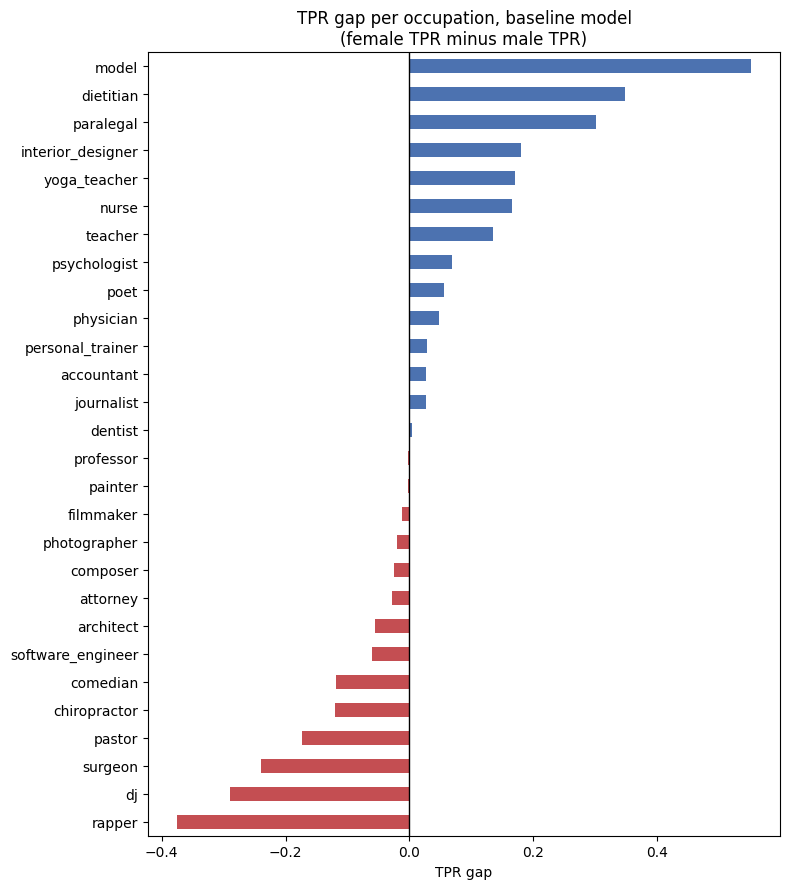

In [5]:
gaps = results["gap"].sort_values()
colors = ["#C44E52" if g < 0 else "#4C72B0" for g in gaps]

plt.figure(figsize=(8, 9))
gaps.plot(kind="barh", color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.title("TPR gap per occupation, baseline model\n(female TPR minus male TPR)")
plt.xlabel("TPR gap")
plt.tight_layout()
plt.savefig("tpr_gap_baseline.png", dpi=150)
plt.show()

## 6. Is the gap bigger where the job is more imbalanced? (RQ2)
Each dot is one occupation: share of women in the training data vs. the model's TPR gap.

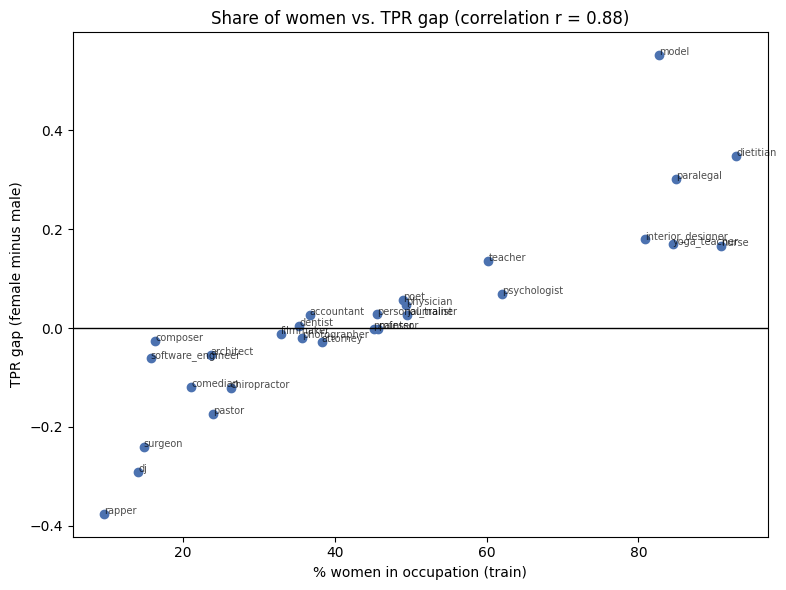

Correlation: 0.88


In [6]:
pct_women = train.groupby("profession")["gender"].mean() * 100
pct_women.index = [PROFESSIONS[i] for i in pct_women.index]
compare = pd.DataFrame({"pct_women": pct_women, "gap": results["gap"]})
corr = compare["pct_women"].corr(compare["gap"])

plt.figure(figsize=(8, 6))
plt.scatter(compare["pct_women"], compare["gap"], color="#4C72B0")
for name, row in compare.iterrows():
    plt.annotate(name, (row["pct_women"], row["gap"]), fontsize=7, alpha=0.7)
plt.axhline(0, color="black", linewidth=1)
plt.title(f"Share of women vs. TPR gap (correlation r = {corr:.2f})")
plt.xlabel("% women in occupation (train)")
plt.ylabel("TPR gap (female minus male)")
plt.tight_layout()
plt.savefig("gap_vs_share_women.png", dpi=150)
plt.show()
print(f"Correlation: {corr:.2f}")

## 7. Log the run in MLflow
MLflow records the model's settings and results, so every later model can be compared with this baseline.

In [7]:
import mlflow

mlflow.set_experiment("bias-audit")
with mlflow.start_run(run_name="baseline_tfidf_logreg"):
    mlflow.log_params({"model": "tfidf_logreg", "train_sample": SAMPLE_SIZE,
                       "max_features": MAX_FEATURES, "C": 4.0})
    mlflow.log_metrics({"accuracy": accuracy, "rms_tpr_gap": overall,
                        "rms_tpr_gap_ci_low": ci_low, "rms_tpr_gap_ci_high": ci_high,
                        "gap_share_women_corr": corr})
    mlflow.log_artifact("tpr_gap_baseline.png")
    mlflow.log_artifact("gap_vs_share_women.png")

results.round(4).to_csv("tpr_results_baseline.csv")
print("Run logged and results saved.")

2026/11/21 15:15:25 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/21 15:15:25 INFO mlflow.store.db.utils: Updating database tables
2026/11/21 15:15:29 INFO mlflow.tracking.fluent: Experiment with name 'bias-audit' does not exist. Creating a new experiment.


Run logged and results saved.


## 8. What I found
The baseline model (TF-IDF with logistic regression) reaches a test accuracy of 0.809. However, its overall bias score (RMS TPR gap) is 0.188, with a 95% confidence interval of 0.175 to 0.209. This is far above the fairness threshold of 0.05, so the model fails the fairness gate.

The largest gaps go against women in male-dominated jobs: only 26.5% of female rappers are recognised compared with 64.0% of male rappers, and for surgeons it is 44.2% compared with 68.2%. In female-dominated jobs such as model, dietitian, paralegal and nurse, the gap goes the other way, and men are recognised less often.

The gap is strongly linked to the gender imbalance of each occupation (correlation r = 0.88). The model learns and reproduces the gender stereotypes in the data, which is exactly what an automatic fairness gate should catch before deployment.